In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

repo_root = Path.cwd()
if not (repo_root / "src" / "unlearn" / "data.py").is_file():
    repo_root = repo_root.parent

src_dir = repo_root / "src"
if not (src_dir / "unlearn" / "data.py").is_file():
    raise FileNotFoundError(f"Could not find src/unlearn/data.py from {Path.cwd()}")
sys.path.insert(0, str(src_dir))

from unlearn.device import DEVICE
from unlearn.data import get_cifar10_loaders
from unlearn.models import load_cifar10_model
from unlearn.metrics import accuracy, mia_accuracy
from unlearn.methods import finetune 
# --> Double check the compatability with the new model and loaders. Hashed out for now, may need to be re-added later.

print("Running on device:", str(DEVICE).upper())

Running on device: MPS


In [2]:
# Load CIFAR-10 and create the train, test, validation, forget, and retain loaders.
loaders = get_cifar10_loaders()
train_loader, test_loader, val_loader = loaders["train"], loaders["test"], loaders["val"]
forget_loader, retain_loader = loaders["forget"], loaders["retain"]

In [3]:
#Calls and loads the pre-trained ResNet18 model for CIFAR-10 from the weights file.
model = load_cifar10_model(repo_root / "weights_resnet18_cifar10.pth")

In [4]:
# Load the challenge's CIFAR-10-pretrained ResNet-18.
import copy

ft_model = finetune.unlearning(copy.deepcopy(model), retain_loader, forget_loader, val_loader)

print(f"Retain acc: {100*accuracy(ft_model, retain_loader):.1f}%")
print(f"Test acc:   {100*accuracy(ft_model, test_loader):.1f}%")
print(f"MIA:        {mia_accuracy(ft_model, forget_loader, test_loader):.3f}")

#This will be the challenge's model that is used for the evaluation of the unlearning methods.
#It is a copy of the original model that has been fine-tuned on the retain and forget datasets.

Retain acc: 98.2%
Test acc:   83.6%
MIA:        0.514


The MIA has an accuracy of 0.514 on forgotten vs unseen images

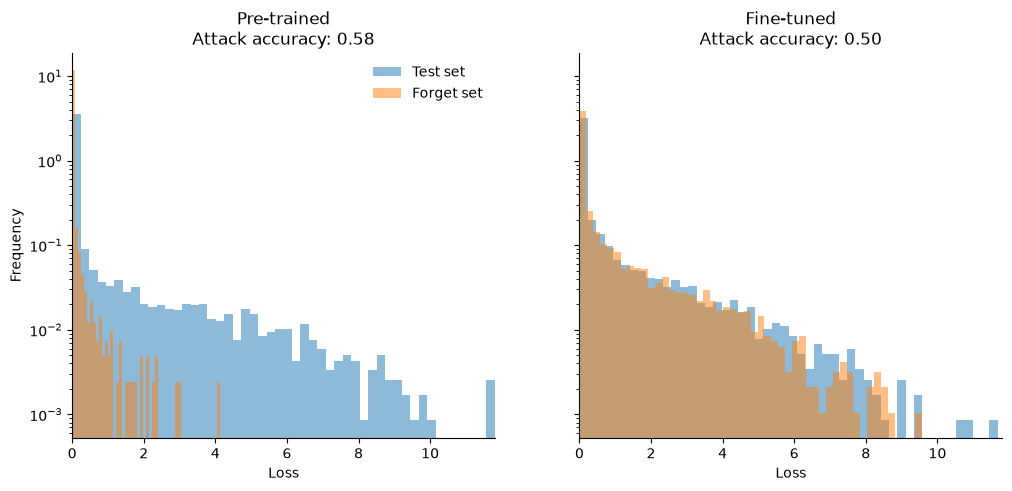

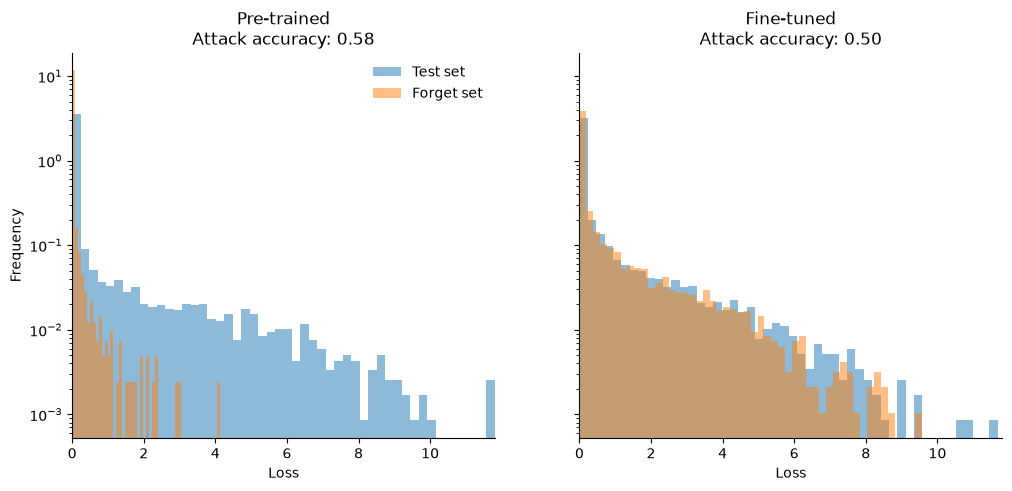

In [15]:
from unlearn.plotGraph import plot_forget_vs_test 

plot_forget_vs_test(
    {"Pre-trained": model, "Fine-tuned": ft_model},
    forget_loader, test_loader,
)

Possibly graph findings, see how different the forget and the retain sets are when it comes to the evaluations.
The following cells will call for the different models to be tested.